# 03. 잉글랜드 축구 2024-25: 피타고라스 기대 승률과 승점

같은 방법을 **잉글랜드 1~4부 리그(프리미어리그·챔피언십·리그1·리그2) 2,036경기**에 적용했다. 무승부가 있어 승리 3점·무승부 1점의 승점을 쓰고, 리그별로 색을 나눠 비교한다.

In [1]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
ENG = pd.read_excel('../data/epl-2025-asplayed.xlsx')
print(ENG.columns.tolist())

['Div', 'Date', 'Time', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR', 'HTHG', 'HTAG', 'HTR', 'Referee', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR', 'B365H', 'B365D', 'B365A', 'BWH', 'BWD', 'BWA', 'BFH', 'BFD', 'BFA', 'PSH', 'PSD', 'PSA', 'WHH', 'WHD', 'WHA', '1XBH', '1XBD', '1XBA', 'MaxH', 'MaxD', 'MaxA', 'AvgH', 'AvgD', 'AvgA', 'BFEH', 'BFED', 'BFEA', 'B365>2.5', 'B365<2.5', 'P>2.5', 'P<2.5', 'Max>2.5', 'Max<2.5', 'Avg>2.5', 'Avg<2.5', 'BFE>2.5', 'BFE<2.5', 'AHh', 'B365AHH', 'B365AHA', 'PAHH', 'PAHA', 'MaxAHH', 'MaxAHA', 'AvgAHH', 'AvgAHA', 'BFEAHH', 'BFEAHA', 'B365CH', 'B365CD', 'B365CA', 'BWCH', 'BWCD', 'BWCA', 'BFCH', 'BFCD', 'BFCA', 'PSCH', 'PSCD', 'PSCA', 'WHCH', 'WHCD', 'WHCA', '1XBCH', '1XBCD', '1XBCA', 'MaxCH', 'MaxCD', 'MaxCA', 'AvgCH', 'AvgCD', 'AvgCA', 'BFECH', 'BFECD', 'BFECA', 'B365C>2.5', 'B365C<2.5', 'PC>2.5', 'PC<2.5', 'MaxC>2.5', 'MaxC<2.5', 'AvgC>2.5', 'AvgC<2.5', 'BFEC>2.5', 'BFEC<2.5', 'AHCh', 'B365CAHH', 'B365CAHA', 'PCAHH', 'PCAHA',

In [3]:
ENG

,Div,Date,Time,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,...,B365CAHH,B365CAHA,PCAHH,PCAHA,MaxCAHH,MaxCAHA,AvgCAHH,AvgCAHA,BFECAHH,BFECAHA
0,E0,16/08/2024,20:00:00,Man United,Fulham,1,0,H,0,0,...,1.86,2.07,1.83,2.11,1.88,2.11,1.82,2.05,1.90,2.08
1,E0,17/08/2024,12:30:00,Ipswich,Liverpool,0,2,A,0,0,...,2.05,1.88,2.04,1.90,2.20,2.00,1.99,1.88,2.04,1.93
2,E0,17/08/2024,15:00:00,Arsenal,Wolves,2,0,H,1,0,...,2.02,1.91,2.00,1.90,2.05,1.93,1.99,1.87,2.02,1.96
3,E0,17/08/2024,15:00:00,Everton,Brighton,0,3,A,0,1,...,1.87,2.06,1.86,2.07,1.92,2.10,1.83,2.04,1.88,2.11
4,E0,17/08/2024,15:00:00,Newcastle,Southampton,1,0,H,1,0,...,1.87,2.06,1.88,2.06,1.89,2.10,1.82,2.05,1.89,2.10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2031,E3,03/05/2025,15:00:00,Morecambe,Harrogate,1,2,A,1,2,...,1.78,2.10,1.74,2.12,1.78,2.18,1.73,2.09,1.81,2.22
2032,E3,03/05/2025,15:00:00,Newport County,Tranmere,1,4,A,1,1,...,1.78,2.03,1.84,2.00,1.84,2.03,1.81,1.98,1.84,2.13
2033,E3,03/05/2025,15:00:00,Notts County,Doncaster,1,2,A,0,2,...,1.80,2.05,1.79,2.06,1.81,2.12,1.76,2.05,1.85,2.15
2034,E3,03/05/2025,15:00:00,Port Vale,Gillingham,0,1,A,0,0,...,2.03,1.83,2.04,1.81,2.05,1.83,2.00,1.80,2.09,1.86


In [4]:
ENG18 = ENG[['Div','Date','HomeTeam','AwayTeam','FTHG','FTAG','FTR']].copy()
ENG18

,Div,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR
0,E0,16/08/2024,Man United,Fulham,1,0,H
1,E0,17/08/2024,Ipswich,Liverpool,0,2,A
2,E0,17/08/2024,Arsenal,Wolves,2,0,H
3,E0,17/08/2024,Everton,Brighton,0,3,A
4,E0,17/08/2024,Newcastle,Southampton,1,0,H
...,...,...,...,...,...,...,...
2031,E3,03/05/2025,Morecambe,Harrogate,1,2,A
2032,E3,03/05/2025,Newport County,Tranmere,1,4,A
2033,E3,03/05/2025,Notts County,Doncaster,1,2,A
2034,E3,03/05/2025,Port Vale,Gillingham,0,1,A


In [5]:
ENG18['hwinval'] = np.where(ENG18['FTR']=='H',3,np.where(ENG18['FTR']=='D',1,0))
ENG18['awinval'] = np.where(ENG18['FTR']=='A',3,np.where(ENG18['FTR']=='D',1,0))
ENG18['count'] = 1

In [6]:
ENGhome = ENG18.groupby(['HomeTeam','Div'])[['count','hwinval','FTHG','FTAG']].sum().reset_index()
ENGhome = ENGhome.rename(columns={'HomeTeam':'team','count':'Ph','FTHG':'FTHGh','FTAG':'FTAGh'})
ENGhome

,team,Div,Ph,hwinval,FTHGh,FTAGh
0,AFC Wimbledon,E3,23,44,35,16
1,Accrington,E3,23,26,29,31
2,Arsenal,E0,19,39,35,17
3,Aston Villa,E0,19,40,34,20
4,Barnsley,E2,23,26,33,36
...,...,...,...,...,...,...
87,West Ham,E0,19,20,23,34
88,Wigan,E2,23,28,20,23
89,Wolves,E0,19,21,27,32
90,Wrexham,E2,23,53,41,15


In [7]:
ENGaway = ENG18.groupby('AwayTeam')[['count','awinval','FTHG','FTAG']].sum().reset_index()
ENGaway = ENGaway.rename(columns={'AwayTeam':'team','count':'Pa','FTHG':'FTHGa','FTAG':'FTAGa'})
ENGaway

,team,Pa,awinval,FTHGa,FTAGa
0,AFC Wimbledon,23,29,19,21
1,Accrington,23,24,38,24
2,Arsenal,19,35,17,34
3,Aston Villa,19,26,31,24
4,Barnsley,23,35,37,36
...,...,...,...,...,...
87,West Ham,19,23,28,23
88,Wigan,23,28,19,20
89,Wolves,19,21,37,27
90,Wrexham,23,39,19,26


In [8]:
ENG18 = pd.merge(ENGhome,ENGaway,on=['team'])
ENG18

,team,Div,Ph,hwinval,FTHGh,FTAGh,Pa,awinval,FTHGa,FTAGa
0,AFC Wimbledon,E3,23,44,35,16,23,29,19,21
1,Accrington,E3,23,26,29,31,23,24,38,24
2,Arsenal,E0,19,39,35,17,19,35,17,34
3,Aston Villa,E0,19,40,34,20,19,26,31,24
4,Barnsley,E2,23,26,33,36,23,35,37,36
...,...,...,...,...,...,...,...,...,...,...
87,West Ham,E0,19,20,23,34,19,23,28,23
88,Wigan,E2,23,28,20,23,23,28,19,20
89,Wolves,E0,19,21,27,32,19,21,37,27
90,Wrexham,E2,23,53,41,15,23,39,19,26


In [9]:
ENG18['W'] = ENG18['hwinval'] + ENG18['awinval']
ENG18['G'] = ENG18['Ph'] + ENG18['Pa']
ENG18['GF'] = ENG18['FTHGh'] + ENG18['FTAGa']
ENG18['GA'] = ENG18['FTAGh'] + ENG18['FTHGa']
ENG18

,team,Div,Ph,hwinval,FTHGh,FTAGh,Pa,awinval,FTHGa,FTAGa,W,G,GF,GA
0,AFC Wimbledon,E3,23,44,35,16,23,29,19,21,73,46,56,35
1,Accrington,E3,23,26,29,31,23,24,38,24,50,46,53,69
2,Arsenal,E0,19,39,35,17,19,35,17,34,74,38,69,34
3,Aston Villa,E0,19,40,34,20,19,26,31,24,66,38,58,51
4,Barnsley,E2,23,26,33,36,23,35,37,36,61,46,69,73
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
87,West Ham,E0,19,20,23,34,19,23,28,23,43,38,46,62
88,Wigan,E2,23,28,20,23,23,28,19,20,56,46,40,42
89,Wolves,E0,19,21,27,32,19,21,37,27,42,38,54,69
90,Wrexham,E2,23,53,41,15,23,39,19,26,92,46,67,34


In [10]:
ENG18['wpc'] = ENG18['W'] / ENG18['G']
ENG18['pyth'] = ENG18['GF']**2 / (ENG18['GF']**2+ENG18['GA']**2)
ENG18

,team,Div,Ph,hwinval,FTHGh,FTAGh,Pa,awinval,FTHGa,FTAGa,W,G,GF,GA,wpc,pyth
0,AFC Wimbledon,E3,23,44,35,16,23,29,19,21,73,46,56,35,1.586957,0.719101
1,Accrington,E3,23,26,29,31,23,24,38,24,50,46,53,69,1.086957,0.371070
2,Arsenal,E0,19,39,35,17,19,35,17,34,74,38,69,34,1.947368,0.804631
3,Aston Villa,E0,19,40,34,20,19,26,31,24,66,38,58,51,1.736842,0.563956
4,Barnsley,E2,23,26,33,36,23,35,37,36,61,46,69,73,1.326087,0.471853
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
87,West Ham,E0,19,20,23,34,19,23,28,23,43,38,46,62,1.131579,0.355034
88,Wigan,E2,23,28,20,23,23,28,19,20,56,46,40,42,1.217391,0.475624
89,Wolves,E0,19,21,27,32,19,21,37,27,42,38,54,69,1.105263,0.379836
90,Wrexham,E2,23,53,41,15,23,39,19,26,92,46,67,34,2.000000,0.795217


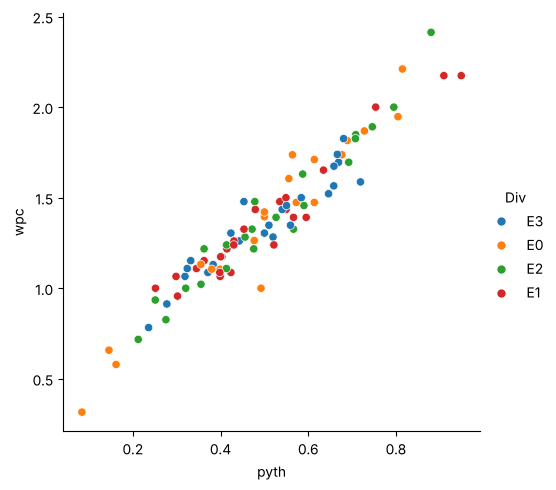

In [11]:
sns.relplot(x="pyth",y="wpc",data=ENG18,hue='Div')

In [12]:
pyth_lm = smf.ols(formula='wpc ~ pyth',data=ENG18).fit()
pyth_lm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    wpc   R-squared:                       0.924
Model:                            OLS   Adj. R-squared:                  0.923
Method:                 Least Squares   F-statistic:                     1093.
Date:                Sat, 31 Oct 2026   Prob (F-statistic):           4.01e-52
Time:                        17:07:12   Log-Likelihood:                 79.195
No. Observations:                  92   AIC:                            -154.4
Df Residuals:                      90   BIC:                            -149.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.3347      0.033     10.121      0.000       0.269       0.400
pyth           2.0605      0.062     33.055      0.000       1.937       2.184
==============================================================================
Omnibus:                        3.895   Durbin-Watson:                   2.260
Prob(Omnibus):                  0.143   Jarque-Bera (JB):                3.750
Skew:                          -0.235   Prob(JB):                        0.153
Kurtosis:                       3.870   Cond. No.                         7.27
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""